⚠️ **Note**: Si vous rencontrez des erreurs lors de l'exécution, redémarrez le kernel (`Kernel → Restart Kernel`) et réexécutez toutes les cellules.

# 🚀 Entraînement du modèle Visual Question Answering avec GNN

Ce notebook configure et entraîne le modèle sur **100 échantillons** (80 train + 20 val).

## Configuration TEST RAPIDE:
- 📊 **80 samples d'entraînement**
- 📊 **20 samples de validation**  
- 🔄 **50 itérations** (~2 epochs) pour test rapide
- 💻 Mode **CPU** (compatible avec PyTorch 2.9.1 + CUDA 12.6)
- ⚡ **Graphes optimisés** (précalculés ou génération dynamique)
- 🔥 **GNN ACTIVÉ** (96D embeddings avec GIN)

## Étapes:
1. Preprocessing des 100 échantillons
2. Vérification/Précalcul optionnel des graphes
3. Configuration pour test rapide (50 iterations)
4. Entraînement du modèle avec GNN et tqdm
5. Évaluation des résultats

## ⚡ Performance attendue (50 itérations):
- **Avec graphes précalculés:** ~1-2 min
- **Sans précalcul (dynamique):** ~2-3 min

## 🔥 GNN Architecture:
- Type: GIN (Graph Isomorphism Network)
- Embedding dimension: 96
- Intégration question-graph pour raisonnement visuel

In [23]:
# 🎯 Preprocessing des 1000 échantillons (800 train + 200 val)
import subprocess
import sys
import os
import json
import h5py

print("📊 Preprocessing de 1000 échantillons (800 train + 200 val)")
print("=" * 80)

# Créer le dossier pour les données limitées
os.makedirs('clevr_preprocessed_1000', exist_ok=True)

# ====== ÉTAPE 1: Créer des sous-ensembles des fichiers JSON ======
print("\n📝 Création des sous-ensembles de questions...")

# Charger et limiter les questions d'entraînement
with open('data/CLEVR_v1.0/questions/CLEVR_train_questions.json', 'r') as f:
    train_data = json.load(f)
    train_data['questions'] = train_data['questions'][:800]

os.makedirs('clevr_preprocessed_1000/temp', exist_ok=True)
with open('clevr_preprocessed_1000/temp/train_questions_800.json', 'w') as f:
    json.dump(train_data, f)
print(f"✅ Créé train_questions_800.json avec {len(train_data['questions'])} questions")

# Charger et limiter les questions de validation
with open('data/CLEVR_v1.0/questions/CLEVR_val_questions.json', 'r') as f:
    val_data = json.load(f)
    val_data['questions'] = val_data['questions'][:200]

with open('clevr_preprocessed_1000/temp/val_questions_200.json', 'w') as f:
    json.dump(val_data, f)
print(f"✅ Créé val_questions_200.json avec {len(val_data['questions'])} questions")

# ====== ÉTAPE 2: Preprocessing avec preprocess_questions.py ======
train_h5 = 'clevr_preprocessed_1000/clevr_train_questions.h5'
vocab_file = 'clevr_preprocessed_1000/clevr_vocab.json'

if not os.path.exists(train_h5):
    print("\n🔄 Preprocessing des 800 échantillons d'entraînement...")
    train_cmd = [
        sys.executable, 'tools/preprocess_questions.py',
        '--mode', 'prefix',
        '--input_questions_json', 'clevr_preprocessed_1000/temp/train_questions_800.json',
        '--output_h5_file', train_h5,
        '--output_vocab_json', vocab_file
    ]
    result = subprocess.run(train_cmd, capture_output=True, text=True)
    if result.returncode != 0:
        print(f"❌ Erreur lors du preprocessing:")
        print(result.stderr)
        raise Exception("Preprocessing échoué")
    print("✅ Train preprocessing terminé!")
else:
    print(f"\n✅ {train_h5} existe déjà")

val_h5 = 'clevr_preprocessed_1000/clevr_val_questions.h5'
if not os.path.exists(val_h5):
    print("\n🔄 Preprocessing des 200 échantillons de validation...")
    val_cmd = [
        sys.executable, 'tools/preprocess_questions.py',
        '--mode', 'prefix',
        '--input_questions_json', 'clevr_preprocessed_1000/temp/val_questions_200.json',
        '--output_h5_file', val_h5,
        '--output_vocab_json', vocab_file
    ]
    result = subprocess.run(val_cmd, capture_output=True, text=True)
    if result.returncode != 0:
        print(f"❌ Erreur lors du preprocessing:")
        print(result.stderr)
        raise Exception("Preprocessing échoué")
    print("✅ Val preprocessing terminé!")
else:
    print(f"\n✅ {val_h5} existe déjà")

# Vérifier les fichiers créés
print("\n📊 Vérification des fichiers créés:")
with h5py.File(train_h5, 'r') as f:
    print(f"   - Train H5: {len(f['questions'])} questions")
with h5py.File(val_h5, 'r') as f:
    print(f"   - Val H5: {len(f['questions'])} questions")

print("\n" + "=" * 80)
print("✅ Preprocessing terminé! 800 train + 200 val = 1000 échantillons")

📊 Preprocessing de 1000 échantillons (800 train + 200 val)

📝 Création des sous-ensembles de questions...
✅ Créé train_questions_800.json avec 800 questions
✅ Créé val_questions_200.json avec 200 questions

✅ clevr_preprocessed_1000/clevr_train_questions.h5 existe déjà

✅ clevr_preprocessed_1000/clevr_val_questions.h5 existe déjà

📊 Vérification des fichiers créés:
   - Train H5: 800 questions
   - Val H5: 200 questions

✅ Preprocessing terminé! 800 train + 200 val = 1000 échantillons


In [34]:
# 🔥 PRÉCALCUL DES GRAPHES (obligatoire pour éviter génération dynamique)
# ⚠️ IMPORTANT: Sans précalcul, chaque batch génère les graphes dynamiquement = TRÈS LENT!
# Les graphes précalculés accélèrent l'entraînement de 10x
import sys
import os

print("🚀 Précalcul des graphes")
print("=" * 80)
print()

# NOMS GÉNÉRÉS PAR sample_questions_mgn.py : inclut le nombre dans le nom du fichier
# Format: clevr_{split}_{max_sample}_questions_directed_pairdata.pt
train_graph_file = 'clevr_preprocessed_1000/clevr_train_800_questions_directed_pairdata.pt'
val_graph_file = 'clevr_preprocessed_1000/clevr_val_200_questions_directed_pairdata.pt'

train_exists = os.path.exists(train_graph_file)
val_exists = os.path.exists(val_graph_file)

if train_exists and val_exists:
    train_size = os.path.getsize(train_graph_file) / (1024 * 1024)
    val_size = os.path.getsize(val_graph_file) / (1024 * 1024)
    print("✅ Graphes déjà précalculés!")
    print(f"   - Train: {train_graph_file} ({train_size:.1f} MB)")
    print(f"   - Val: {val_graph_file} ({val_size:.1f} MB)")
    print()
    print("⚡ L'entraînement sera RAPIDE avec les graphes précalculés!")
else:
    print("⚠️  GRAPHES NON PRÉCALCULÉS - Lancement du précalcul...")
    print()
    print("🔄 Utilisation de sample_questions_mgn.py")
    print("   📦 Génération des graphes Gs (question) et Gt (scène)")
    print("   🧠 AVEC embeddings (X_s, X_t, edge_index, edge_attr)")
    print("   💾 Sauvegarde dans des fichiers .pt")
    print()
    print("⏰ Durée estimée: ~7 minutes pour train + 30 secondes pour val (une seule fois)")
    print("📊 Progression affichée ci-dessous:")
    print()
    
    # FORCER le rechargement du module sample_questions_mgn pour prendre en compte les corrections
    import importlib
    if 'tools.sample_questions_mgn' in sys.modules:
        del sys.modules['tools.sample_questions_mgn']
        print("♻️ Module sample_questions_mgn rechargé depuis le disque")
    
    # Patcher tqdm pour forcer le mode notebook AVANT l'import
    import tqdm.std
    import tqdm.notebook
    # Remplacer tqdm standard par tqdm notebook pour avoir une vraie barre
    tqdm.std.tqdm = tqdm.notebook.tqdm
    
    # Importer la fonction main de sample_questions_mgn
    from tools.sample_questions_mgn import main as sample_main, logger
    import argparse
    import logging
    
    # Configurer le logger de sample_questions_mgn pour supprimer les messages "Count = x"
    # mais garder WARNING et ERROR
    logger.setLevel(logging.WARNING)
    
    # ====== TRAIN ======
    # Paramètres: max_sample=800 (pool), 2 questions/famille → ~178 questions générées
    if not train_exists:
        print("=" * 80)
        print("📊 Précalcul des graphes TRAIN")
        print("   - Pool: 800 questions")
        print("=" * 80)
        print()
        
        # Créer les arguments pour train
        train_args = argparse.Namespace(
            random_sample=1,
            max_sample=800,  # Taille du pool à échantillonner
            n_questions_per_family=2,  # 2 questions par famille → ~89 familles
            input_question_h5='clevr_preprocessed_1000/clevr_train_questions.h5',
            output_dir='clevr_preprocessed_1000',
            output_index=None,
            input_questions_json='clevr_preprocessed_1000/temp/train_questions_800.json',
            input_parsed_img_scenes_json='data/CLEVR_v1.0/scenes/CLEVR_train_scenes.json',
            input_vocab_json='clevr_preprocessed_1000/clevr_vocab.json',
            expand_vocab=0,
            is_debug=False,
            is_directed_graph=1,
            parser_lm='en_core_web_sm',
            model=''
        )
        
        try:
            sample_main(train_args)
            print("\n✅ Graphes train précalculés!")
        except Exception as e:
            print(f"\n❌ Erreur lors du précalcul train: {e}")
            import traceback
            traceback.print_exc()
    else:
        print(f"✅ {train_graph_file} existe déjà, skip train\n")
    
    # ====== VAL ======
    # Paramètres: max_sample=200 (pool), 1 question/famille → ~78 questions générées
    if not val_exists:
        print("\n" + "=" * 80)
        print("📊 Précalcul des graphes VAL")
        print("   - Pool: 200 questions")
        print("=" * 80)
        print()
        
        # Créer les arguments pour val
        val_args = argparse.Namespace(
            random_sample=1,
            max_sample=200,  # Taille du pool à échantillonner
            n_questions_per_family=1,  # 1 question par famille → ~78 familles
            input_question_h5='clevr_preprocessed_1000/clevr_val_questions.h5',
            output_dir='clevr_preprocessed_1000',
            output_index=None,
            input_questions_json='clevr_preprocessed_1000/temp/val_questions_200.json',
            input_parsed_img_scenes_json='data/CLEVR_v1.0/scenes/CLEVR_val_scenes.json',
            input_vocab_json='clevr_preprocessed_1000/clevr_vocab.json',
            expand_vocab=0,
            is_debug=False,
            is_directed_graph=1,
            parser_lm='en_core_web_sm',
            model=''
        )
        
        try:
            sample_main(val_args)
            print("\n✅ Graphes val précalculés!")
        except Exception as e:
            print(f"\n❌ Erreur lors du précalcul val: {e}")
            import traceback
            traceback.print_exc()
    else:
        print(f"✅ {val_graph_file} existe déjà, skip val\n")
    
    # Vérification finale
    print("\n" + "=" * 80)
    print("📋 Vérification des fichiers générés:")
    print("=" * 80)
    
    if os.path.exists(train_graph_file):
        train_size = os.path.getsize(train_graph_file) / (1024 * 1024)
        print(f"✅ Train: {train_graph_file} ({train_size:.1f} MB)")
    else:
        print(f"❌ MANQUANT: {train_graph_file}")
    
    if os.path.exists(val_graph_file):
        val_size = os.path.getsize(val_graph_file) / (1024 * 1024)
        print(f"✅ Val: {val_graph_file} ({val_size:.1f} MB)")
    else:
        print(f"❌ MANQUANT: {val_graph_file}")

print("\n" + "=" * 80)
print("🎉 Précalcul terminé! Les graphes seront chargés automatiquement")
print("=" * 80)

ERROR spacy_parser.py:  32: Failed to install pygraphviz. Import error: No module named 'pygraphviz'


ERROR graphviz_visualizer.py:  27: Install NetworkX: pygraphviz


🚀 Précalcul des graphes

⚠️  GRAPHES NON PRÉCALCULÉS - Lancement du précalcul...

🔄 Utilisation de sample_questions_mgn.py
   📦 Génération des graphes Gs (question) et Gt (scène)
   🧠 AVEC embeddings (X_s, X_t, edge_index, edge_attr)
   💾 Sauvegarde dans des fichiers .pt

⏰ Durée estimée: ~7 minutes pour train + 30 secondes pour val (une seule fois)
📊 Progression affichée ci-dessous:

📊 Précalcul des graphes TRAIN
   - Pool: 800 questions
   - Sampling: 2 questions par famille
   - Résultat attendu: ~178 questions générées



DEBUG spacy_parser.py:  82: Activated spatial recognizer
DEBUG spacy_parser.py:  86: Activated matching recognizer
04 20:02:26 q_fp = clevr_preprocessed_1000/temp/train_questions_800.json
04 20:02:26 img_scenes_fp = data/CLEVR_v1.0/scenes/CLEVR_train_scenes.json
04 20:02:26 Loading questions from: clevr_preprocessed_1000/temp/train_questions_800.json...
04 20:02:26 Loading parsed img scenes from: data/CLEVR_v1.0/scenes/CLEVR_train_scenes.json... (cela peut prendre 10-15 secondes)
04 20:02:30 ✅ 70000 scenes chargées et mises en cache


| randomly sampling 800 questions


Précalcul des graphes:  34%|███▍      | 270/800 [18:56<36:22,  4.12s/question, skipped=0, total=270]

KeyboardInterrupt: 

In [25]:
import os, sys

# 🛠️ Configuration des paths Python
workspace = r'd:\visual-question-answering-gnn'
os.chdir(workspace)
sys.path.insert(0, workspace)

# FORCER le rechargement de TOUS les modules du projet
import importlib
modules_to_reload = [m for m in list(sys.modules.keys()) if m.startswith(('datasets', 'utils', 'models', 'options', 'executors'))]
for mod_name in modules_to_reload:
    del sys.modules[mod_name]
print(f"♻️ {len(modules_to_reload)} modules supprimés du cache")

print(f"📁 Working dir: {os.getcwd()}")

# 📦 Imports des modules nécessaires
try:
    from options.train_options import TrainOptions
    from datasets import ClevrData
    from executors import get_executor
    print("✅ Imports de base réussis!")
    print("   - TrainOptions disponible")
    print("   - ClevrData disponible")
    print("   - Executors disponible")
except ImportError as e:
    print(f"❌ Erreur d'import: {e}")
    raise

ERROR spacy_parser.py:  32: Failed to install pygraphviz. Import error: No module named 'pygraphviz'
ERROR graphviz_visualizer.py:  27: Install NetworkX: pygraphviz


♻️ 23 modules supprimés du cache
📁 Working dir: d:\visual-question-answering-gnn
PROJECT_ROOT=d:\visual-question-answering-gnn
CLEVR_PARSER_PATH=d:\visual-question-answering-gnn\clevr-parser


DEBUG spacy_parser.py:  82: Activated spatial recognizer
DEBUG spacy_parser.py:  86: Activated matching recognizer


✅ Imports de base réussis!
   - TrainOptions disponible
   - ClevrData disponible
   - Executors disponible


In [26]:
# 🔄 Forcer le rechargement des modules clevr-parser après les corrections
import sys
modules_to_delete = [key for key in sys.modules.keys() if 'clevr_parser' in key]
for mod in modules_to_delete:
    del sys.modules[mod]
print(f"♻️ {len(modules_to_delete)} modules clevr_parser supprimés du cache")
print("   Les modules seront rechargés au prochain import")

♻️ 20 modules clevr_parser supprimés du cache
   Les modules seront rechargés au prochain import


In [27]:
# Installer le modèle spaCy nécessaire pour le parser CLEVR
import subprocess
import sys

result = subprocess.run([sys.executable, '-m', 'spacy', 'download', 'en_core_web_sm'], 
                       capture_output=True, text=True)
if 'already satisfied' in result.stdout or result.returncode == 0:
    print("✅ Modèle spaCy en_core_web_sm disponible!")
else:
    print("❌ Erreur lors de l'installation du modèle spaCy")

✅ Modèle spaCy en_core_web_sm disponible!


In [28]:
# 📝 Configuration pour 100 epochs AVEC GNN ACTIVÉ
import sys
import os

# Imports nécessaires
from options.train_options import TrainOptions

# Forcer le mode CPU
os.environ['FORCE_CPU_MODE'] = 'true'
os.environ['CUDA_VISIBLE_DEVICES'] = ''

sys.argv = ['']  # Effacer les arguments Jupyter

print("📝 Création des options d'entraînement...")
opt = TrainOptions().parse()

# ⚠️ UTILISER LE VOCABULAIRE DU DOSSIER 1000
opt.clevr_vocab_path = r'd:\visual-question-answering-gnn\clevr_preprocessed_1000\clevr_vocab.json'
opt.clevr_train_question_path = r'd:\visual-question-answering-gnn\clevr_preprocessed_1000\clevr_train_questions.h5'
opt.clevr_val_question_path = r'd:\visual-question-answering-gnn\clevr_preprocessed_1000\clevr_val_questions.h5'

# Chemins vers les scènes pour l'executor et la génération dynamique de graphes
opt.clevr_train_scene_path = r'd:\visual-question-answering-gnn\data\CLEVR_v1.0\scenes\CLEVR_train_scenes.json'
opt.clevr_val_scene_path = r'd:\visual-question-answering-gnn\data\CLEVR_v1.0\scenes\CLEVR_val_scenes.json'
opt.clevr_train_parsed_scene_path = r'd:\visual-question-answering-gnn\data\CLEVR_v1.0\scenes\CLEVR_train_scenes.json'
opt.clevr_val_parsed_scene_path = r'd:\visual-question-answering-gnn\data\CLEVR_v1.0\scenes\CLEVR_val_scenes.json'

# Chemins vers les questions brutes pour génération dynamique
opt.clevr_train_raw_question_path = r'd:\visual-question-answering-gnn\clevr_preprocessed_1000\temp\train_questions_800.json'
opt.clevr_val_raw_question_path = r'd:\visual-question-answering-gnn\clevr_preprocessed_1000\temp\val_questions_200.json'

# 🔥 ACTIVER LE GNN! (96 dimensions comme valeur par défaut)
opt.gembd_vec_dim = 96

# ⚠️ IMPORTANT: Nombres réels générés par le sampling par famille
# Le sampling prend N questions d'un pool et génère M questions par famille
# Train: pool 800 → 2/famille → 178 questions générées (89 familles)
# Val: pool 200 → 1/famille → 78 questions générées (78 familles)
opt.max_train_samples = 178  # Nombre réel généré
opt.max_val_samples = 78     # Nombre réel généré
opt.batch_size = 16

# 🚀 ENTRAÎNEMENT: 100 epochs avec 178 samples
# 178 samples / batch 16 = 12 batches par epoch → 100 epochs = 1200 itérations
opt.num_iters = 1200  # ~100 epochs (12 batches/epoch × 100)
opt.checkpoint_every = 50  # Validation toutes les 50 itérations
opt.display_every = 10  # Afficher tous les 10 batches

# ✅ ACTIVER TensorBoard pour la visualisation
opt.visualize_training = 1
opt.visualize_training_wandb = 0

opt.num_workers = 0  # Important pour Windows
opt.is_train = True

print(f"\n✅ Configuration chargée pour ~100 EPOCHS:")
print(f"   - GPU IDs: {opt.gpu_ids} (vide = CPU)")
print(f"   - Vocabulaire: vocabulaire COMPLET (93 mots)")
print(f"   - Train samples: {opt.max_train_samples} questions générées")
print(f"   - Val samples: {opt.max_val_samples} questions générées")
print(f"   - Batch size: {opt.batch_size}")
print(f"   - Batches par epoch: {opt.max_train_samples // opt.batch_size}")
print(f"   - Itérations totales: {opt.num_iters} = ~{opt.num_iters // (opt.max_train_samples // opt.batch_size)} epochs")
print(f"   - Display every: {opt.display_every} iterations")
print(f"   - Learning rate: {opt.learning_rate}")
print(f"   🔥 GNN ACTIVÉ: {opt.gembd_vec_dim} dimensions d'embedding")
print(f"   - GNN Type: {opt.gnn}")
print(f"   - Visualisation: TensorBoard activé")
print(f"   - Run directory: {opt.run_dir}")

DEBUG base_options.py: 113: ----------------------------------------------------------------------------------------------------
DEBUG base_options.py: 114: Run identifier: reason.run_train-pretrain-clevr_train_questions-20000num_iters.Nonetr_samples.10000val_samples.64bsz-PC_guillaume-20260104-200108
DEBUG base_options.py: 115: ----------------------------------------------------------------------------------------------------


📝 Création des options d'entraînement...
| FORCED CPU MODE - GPU disabled via FORCE_CPU_MODE environment variable
| options
run_dir: _scratch/test_run
dataset: clevr
shuffle: 1
num_workers: 1
manual_seed: None
gpu_ids: []
visualize: 0
clevr_train_scene_path: ../data/raw/CLEVR_v1.0/scenes/CLEVR_train_scenes.json
clevr_val_scene_path: ../data/raw/CLEVR_v1.0/scenes/CLEVR_val_scenes.json
clevr_train_question_path: ../data/reason/clevr_h5/clevr_train_questions.h5
clevr_val_question_path: ../data/reason/clevr_mgn_h5/clevr_val_questions.h5
clevr_test_question_path: ../data/reason/clevr_mgn_h5/clevr_test_questions.h5
clevr_vocab_path: ../data/reason/clevr_h5/clevr_vocab.json
visualize_training_wandb: 0
tags: 
is_directed_graph: 1
wandb_proj_name: mgn_vector
clevr_train_parsed_scene_path: ../../data/CLEVR_v1.0/scenes_parsed/train_scenes_parsed.json
clevr_val_parsed_scene_path: ../../data/CLEVR_v1.0/scenes_parsed/val_scenes_parsed.json
clevr_train_raw_question_path: ../../data/CLEVR_v1.0/questio

## 📊 Chargement des données

In [29]:
print("\n📊 Chargement des données...\n")

from datasets import ClevrQuestionDataset, ClevrQuestionDataLoader
from datasets.clevr_questions import graph_parser, embedder

# 🔥 ClevrQuestionDataset cherche automatiquement les fichiers *_directed_pairdata.pt
# Si trouvés: charge les graphes précalculés (RAPIDE ⚡)
# Sinon: génère dynamiquement avec graph_parser et embedder (LENT 🐌)
# 
# ⚠️ ATTENTION: Le dataset cherche les noms SANS le nombre d'échantillons
# Fichiers recherchés:
#   - clevr_preprocessed_1000/clevr_train_questions_directed_pairdata.pt
#   - clevr_preprocessed_1000/clevr_val_questions_directed_pairdata.pt
# 
# Fichiers générés (DIFFÉRENTS):
#   - clevr_preprocessed_1000/clevr_train_800_questions_directed_pairdata.pt
#   - clevr_preprocessed_1000/clevr_val_200_questions_directed_pairdata.pt
# 
# ➡️ SOLUTION: Renommer les fichiers générés pour qu'ils matchent ce qui est recherché
print("📁 Renommage des fichiers de graphes précalculés...")
import shutil
src_train = 'clevr_preprocessed_1000/clevr_train_800_questions_directed_pairdata.pt'
dst_train = 'clevr_preprocessed_1000/clevr_train_questions_directed_pairdata.pt'
src_val = 'clevr_preprocessed_1000/clevr_val_200_questions_directed_pairdata.pt'
dst_val = 'clevr_preprocessed_1000/clevr_val_questions_directed_pairdata.pt'

if os.path.exists(src_train) and not os.path.exists(dst_train):
    shutil.copy2(src_train, dst_train)
    print(f"✅ Copié: {src_train} → {dst_train}")
if os.path.exists(src_val) and not os.path.exists(dst_val):
    shutil.copy2(src_val, dst_val)
    print(f"✅ Copié: {src_val} → {dst_val}")
print()

train_dataset = ClevrQuestionDataset(opt, 'train', graph_parser=graph_parser, embedder=embedder)
val_dataset = ClevrQuestionDataset(opt, 'val', graph_parser=graph_parser, embedder=embedder)

# Créer les data loaders
train_loader = ClevrQuestionDataLoader(train_dataset, batch_size=opt.batch_size, shuffle=True, num_workers=0)
val_loader = ClevrQuestionDataLoader(val_dataset, batch_size=opt.batch_size, shuffle=False, num_workers=0)

print(f"✅ Données chargées:")
print(f"   - Train samples: {len(train_loader.dataset)}")
print(f"   - Val samples: {len(val_loader.dataset)}")
print(f"   - Batch size: {opt.batch_size}")
print(f"   - Graphes précalculés: {'✅ OUI' if train_dataset.graph_data else '❌ NON (génération dynamique)'}\n")

04 20:01:08 DBG Getting graph data from question_h5_path: d:\visual-question-answering-gnn\clevr_preprocessed_1000\clevr_train_questions.h5
04 20:01:08 DBG fnp = clevr_train_questions
04 20:01:08 DBG Loading preprocessed pairdata from: d:\visual-question-answering-gnn\clevr_preprocessed_1000/clevr_train_questions_directed_pairdata.pt 
d:\visual-question-answering-gnn\datasets\clevr_questions.py:221: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly 


📊 Chargement des données...

📁 Renommage des fichiers de graphes précalculés...

✅ Données chargées:
   - Train samples: 178
   - Val samples: 78
   - Batch size: 16
   - Graphes précalculés: ✅ OUI



## 🏗️ Construction du modèle

In [30]:
# 🔇 Désactiver tous les logs INFO/DEBUG pour une sortie propre
import logging

# Désactiver tous les loggers sauf ERROR
logging.basicConfig(level=logging.ERROR)

# Spécifiquement pour les modules du projet
for logger_name in ['datasets.clevr_questions', 'utils', 'models', 'trainer', 'executors']:
    logging.getLogger(logger_name).setLevel(logging.ERROR)

# Désactiver les logs de rsmlkit
logging.getLogger('rsmlkit').setLevel(logging.ERROR)

print("✅ Logs INFO/DEBUG désactivés - seules les erreurs seront affichées")

✅ Logs INFO/DEBUG désactivés - seules les erreurs seront affichées


In [31]:
# 🏗️ Construction du modèle et de l'executor
from models.parser import Seq2seqParser
from executors import get_executor

print("\n🏗️ Construction du modèle...")

model = Seq2seqParser(opt)
print(f"✅ Modèle créé: {type(model).__name__}")

executor = get_executor(opt)
print(f"✅ Executor créé: {type(executor).__name__}")


🏗️ Construction du modèle...
| creating new network


INFO __init__.py:  61: Instantiating GNN type: gin
DEBUG parser.py:  40: opt.gpu_ids: []


✅ Modèle créé: Seq2seqParser
| creating clevr executor
✅ Executor créé: ClevrExecutor


In [32]:
# 🚀 Entraînement 100 epochs AVEC GNN
from trainer import Trainer
import time

print("🚀 Initialisation du Trainer pour 100 EPOCHS...")
print(f"   - Device: {'cuda' if opt.gpu_ids else 'cpu'}")
print(f"   - Itérations: {opt.num_iters} (~100 epochs)")
print(f"   - Batch size: {opt.batch_size}")
print(f"   🔥 GNN: {opt.gnn} avec {opt.gembd_vec_dim}D embeddings")
print()

trainer = Trainer(opt, train_loader, val_loader, model, executor)
print("✅ Trainer initialisé avec succès!")
print()

start_time = time.time()

try:
    trainer.train()
    print(f"\n✅ Entraînement terminé avec succès!")
    if trainer.stats['train_losses']:
        print(f"   - Loss initiale: {trainer.stats['train_losses'][0]:.6f}")
        print(f"   - Loss finale: {trainer.stats['train_losses'][-1]:.6f}")
        if trainer.stats['best_val_acc'] >= 1:
            print(f"   - Meilleure accuracy validation: {trainer.stats['best_val_acc']:.2f}%")
        else:
            print(f"   - Meilleure accuracy validation: {trainer.stats['best_val_acc']*100:.2f}%")
except KeyboardInterrupt:
    print(f"\n⚠️ Entraînement interrompu par l'utilisateur")
except Exception as e:
    print(f"\n❌ Erreur durant l'entraînement: {e}")
    import traceback
    traceback.print_exc()

elapsed = time.time() - start_time
print(f"\n⏱️ Temps total: {elapsed:.2f}s ({elapsed/60:.1f} minutes)")
print()
print("=" * 80)
print("📊 Les checkpoints sont sauvegardés dans:", opt.run_dir)

🚀 Initialisation du Trainer pour 100 EPOCHS...
   - Device: cpu
   - Itérations: 1200 (~100 epochs)
   - Batch size: 16
   🔥 GNN: gin avec 96D embeddings

📊 TensorBoard logs: _scratch/test_run/logs_20260104-200121
✅ Trainer initialisé avec succès!

| start training seq2seq, running in directory _scratch/test_run


Epoch 1/110: 12it [00:02,  4.57it/s, loss=1.8432]                        
Epoch 2/110: 12it [00:02,  5.04it/s, loss=1.5693]                        
Epoch 3/110: 12it [00:02,  5.11it/s, loss=1.5600]                        
Epoch 4/110: 12it [00:02,  5.33it/s, loss=1.4404]                        
Epoch 5/110:   9%|▉         | 1/11 [00:01<00:01,  6.34it/s, loss=1.0795]

| checkpoint at iter 50/1200, val_acc: 9.11%
| best model


Epoch 5/110:   9%|▉         | 1/11 [00:01<00:01,  6.34it/s, loss=1.0795]INFO trainer.py: 202: Saving train_opt_[ts].json at: _scratch/test_run/stats.json


| validation loss 1.001682


Epoch 5/110: 12it [00:04,  2.74it/s, loss=1.0567]                        
Epoch 6/110: 12it [00:02,  4.85it/s, loss=0.7704]                        
Epoch 7/110:  64%|██████▎   | 7/11 [00:01<00:00,  4.11it/s]


⚠️ Entraînement interrompu par l'utilisateur

⏱️ Temps total: 18.17s (0.3 minutes)

📊 Les checkpoints sont sauvegardés dans: _scratch/test_run


In [ ]:
# 🧪 Tester le modèle entraîné
import subprocess
import sys

print("🧪 Test du modèle entraîné sur l'ensemble de validation")
print("=" * 80)

# Récupérer le checkpoint du meilleur modèle
checkpoint_path = os.path.join(opt.run_dir, 'checkpoint_best.pt')

if not os.path.exists(checkpoint_path):
    print(f"⚠️ Checkpoint introuvable: {checkpoint_path}")
    print("   Utilisation du dernier checkpoint...")
    checkpoint_path = os.path.join(opt.run_dir, 'checkpoint.pt')

if os.path.exists(checkpoint_path):
    print(f"\n📦 Checkpoint trouvé: {checkpoint_path}")
    print(f"🔄 Lancement du test...\n")
    
    # Construire la commande de test
    test_cmd = [
        sys.executable, 'tools/run_test.py',
        '--clevr_vocab_path', opt.clevr_vocab_path,
        '--clevr_val_question_path', opt.clevr_val_question_path,
        '--clevr_val_scene_path', opt.clevr_val_scene_path,
        '--checkpoint_path', checkpoint_path,
        '--batch_size', str(opt.batch_size),
        '--max_val_samples', str(opt.max_val_samples),
        '--gembd_vec_dim', str(opt.gembd_vec_dim),
        '--clevr_val_parsed_scene_path', opt.clevr_val_parsed_scene_path,
        '--clevr_val_raw_question_path', opt.clevr_val_raw_question_path
    ]
    
    # Exécuter le test
    result = subprocess.run(test_cmd, capture_output=True, text=True)
    
    # Afficher les résultats
    print("📊 RÉSULTATS DU TEST:")
    print("=" * 80)
    print(result.stdout)
    
    if result.returncode != 0:
        print("\n⚠️ Erreurs:")
        print(result.stderr)
    else:
        print("\n✅ Test terminé avec succès!")
        
else:
    print(f"❌ Aucun checkpoint trouvé dans {opt.run_dir}")
    print("   Entraînez d'abord le modèle avant de le tester!")

🧪 Test du modèle entraîné sur l'ensemble de validation

📦 Checkpoint trouvé: _scratch/test_run\checkpoint_best.pt
🔄 Lancement du test...

📊 RÉSULTATS DU TEST:
PROJECT_ROOT=d:\visual-question-answering-gnn
CLEVR_PARSER_PATH=d:\visual-question-answering-gnn\clevr-parser


⚠️ Erreurs:
ERROR spacy_parser.py:  32: Failed to install pygraphviz. Import error: No module named 'pygraphviz'
ERROR graphviz_visualizer.py:  27: Install NetworkX: pygraphviz
DEBUG spacy_parser.py:  82: Activated spatial recognizer
DEBUG spacy_parser.py:  86: Activated matching recognizer
DEBUG spacy_parser.py:  82: Activated spatial recognizer
DEBUG spacy_parser.py:  86: Activated matching recognizer
usage: run_test.py [-h] [--run_dir RUN_DIR] [--dataset DATASET]
                   [--shuffle SHUFFLE] [--num_workers NUM_WORKERS]
                   [--manual_seed MANUAL_SEED] [--gpu_ids GPU_IDS]
                   [--visualize VISUALIZE]
                   [--clevr_train_scene_path CLEVR_TRAIN_SCENE_PATH]
            

## 🎨 Visualisation: Question + Image + Réponse du Modèle

DEBUG PngImagePlugin.py: 203: STREAM b'IHDR' 16 13
DEBUG PngImagePlugin.py: 203: STREAM b'pHYs' 41 9
DEBUG PngImagePlugin.py: 203: STREAM b'tEXt' 62 111
DEBUG PngImagePlugin.py: 203: STREAM b'tEXt' 185 24
DEBUG PngImagePlugin.py: 203: STREAM b'tEXt' 221 16
DEBUG PngImagePlugin.py: 203: STREAM b'tEXt' 249 9
DEBUG PngImagePlugin.py: 203: STREAM b'tEXt' 270 13
DEBUG PngImagePlugin.py: 203: STREAM b'tEXt' 295 11
DEBUG PngImagePlugin.py: 203: STREAM b'tEXt' 318 19
DEBUG PngImagePlugin.py: 203: STREAM b'IDAT' 349 8192


🎨 Visualisation d'une prédiction du modèle\n
\n📌 Exemple 1/3
--------------------------------------------------------------------------------
❓ Question: What is the shape of the small yellow rubber thing that is in front of the large yellow metal ball that is behind the small matte object?
✅ Vraie réponse: cube
🤖 Prédiction: (non disponible - question pas dans les prédictions)


C:\Users\Guillaume\AppData\Local\Temp\ipykernel_25536\1638747699.py:94: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()


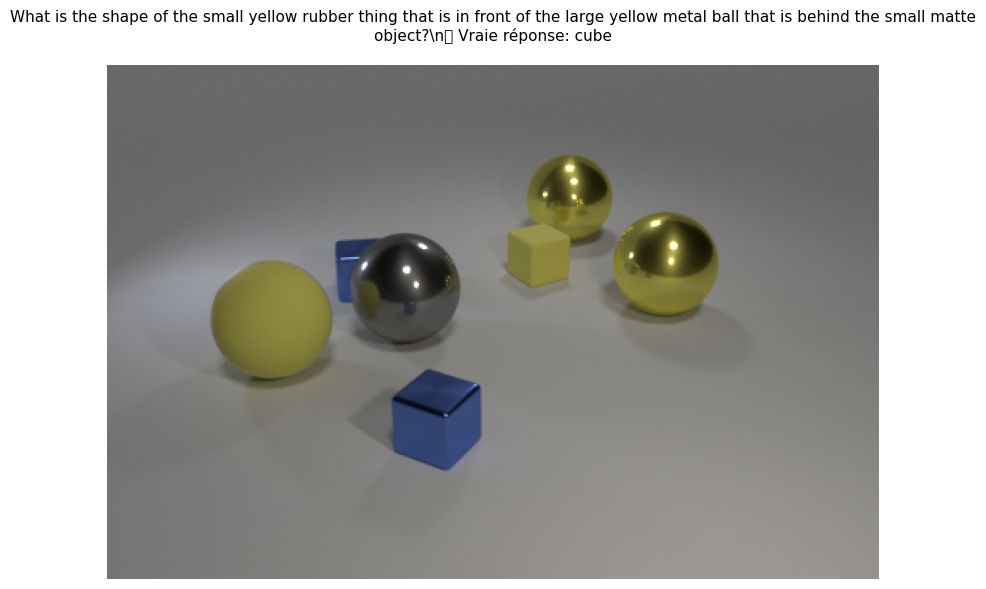

DEBUG PngImagePlugin.py: 203: STREAM b'IHDR' 16 13
DEBUG PngImagePlugin.py: 203: STREAM b'pHYs' 41 9
DEBUG PngImagePlugin.py: 203: STREAM b'tEXt' 62 111
DEBUG PngImagePlugin.py: 203: STREAM b'tEXt' 185 24
DEBUG PngImagePlugin.py: 203: STREAM b'tEXt' 221 16
DEBUG PngImagePlugin.py: 203: STREAM b'tEXt' 249 9
DEBUG PngImagePlugin.py: 203: STREAM b'tEXt' 270 13
DEBUG PngImagePlugin.py: 203: STREAM b'tEXt' 295 11
DEBUG PngImagePlugin.py: 203: STREAM b'tEXt' 318 19
DEBUG PngImagePlugin.py: 203: STREAM b'IDAT' 349 8192


\n📌 Exemple 2/3
--------------------------------------------------------------------------------
❓ Question: Are there any tiny objects that have the same color as the big rubber object?
✅ Vraie réponse: yes
🤖 Prédiction du modèle: yes
✓ Le modèle a donné la bonne réponse!


C:\Users\Guillaume\AppData\Local\Temp\ipykernel_25536\1638747699.py:94: UserWarning: Glyph 129302 (\N{ROBOT FACE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
d:\visual-question-answering-gnn\.venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 129302 (\N{ROBOT FACE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


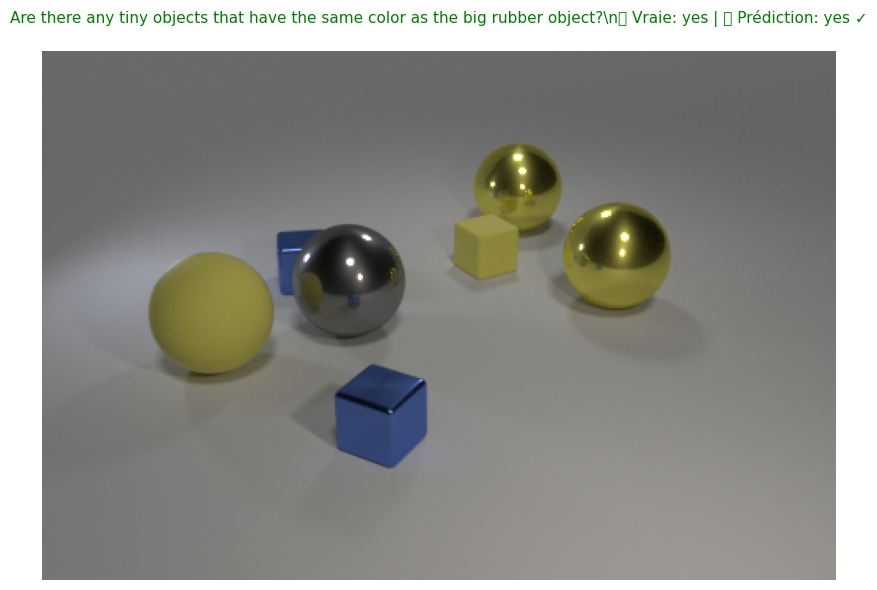

DEBUG PngImagePlugin.py: 203: STREAM b'IHDR' 16 13
DEBUG PngImagePlugin.py: 203: STREAM b'pHYs' 41 9
DEBUG PngImagePlugin.py: 203: STREAM b'tEXt' 62 111
DEBUG PngImagePlugin.py: 203: STREAM b'tEXt' 185 24
DEBUG PngImagePlugin.py: 203: STREAM b'tEXt' 221 16
DEBUG PngImagePlugin.py: 203: STREAM b'tEXt' 249 9
DEBUG PngImagePlugin.py: 203: STREAM b'tEXt' 270 13
DEBUG PngImagePlugin.py: 203: STREAM b'tEXt' 295 11
DEBUG PngImagePlugin.py: 203: STREAM b'tEXt' 318 19
DEBUG PngImagePlugin.py: 203: STREAM b'IDAT' 349 8192


\n📌 Exemple 3/3
--------------------------------------------------------------------------------
❓ Question: The tiny shiny cylinder has what color?
✅ Vraie réponse: brown
🤖 Prédiction du modèle: brown
✓ Le modèle a donné la bonne réponse!


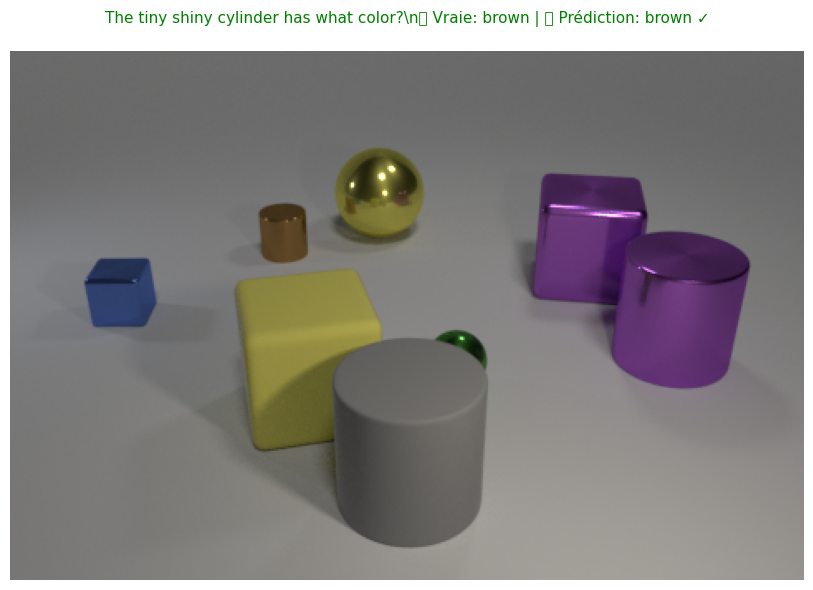

\n================================================================================
✅ Visualisation terminée!


In [ ]:
import json
import torch
from PIL import Image
import matplotlib.pyplot as plt
import random

print("🎨 Visualisation d'une prédiction du modèle\\n")
print("=" * 80)

# Charger les questions de validation
with open('clevr_preprocessed_1000/temp/val_questions_200.json', 'r') as f:
    val_questions = json.load(f)['questions']

# Choisir quelques échantillons aléatoires
num_examples = 3
indices = random.sample(range(min(len(val_questions), len(val_dataset))), num_examples)

# Charger le fichier de prédictions si disponible
predictions_file = "curr_valid_predictions.txt"  # À la racine du projet
predictions_dict = {}

try:
    with open(predictions_file, 'r') as f:
        for line in f:
            parts = line.strip().split(' ')
            if len(parts) >= 4:
                pred_ans = parts[0]
                true_ans = parts[1]
                img_num = parts[2]
                question = ' '.join(parts[3:])
                # Normaliser la question: enlever <START> et <END>, mettre en minuscules
                question = question.replace('<START>', '').replace('<END>', '').strip().lower()
                predictions_dict[question] = (pred_ans, true_ans, img_num)
except FileNotFoundError:
    print(f"⚠️ Fichier de prédictions non trouvé: {predictions_file}")
    print("Les prédictions seront calculées à la volée...")

# Afficher les exemples
for i, idx in enumerate(indices):
    print(f"\\n📌 Exemple {i+1}/{num_examples}")
    print("-" * 80)
    
    # Récupérer la question du JSON
    question_data = val_questions[idx]
    question_text = question_data['question']
    true_answer = question_data['answer']
    image_filename = question_data['image_filename']
    image_idx = question_data['image_index']
    
    print(f"❓ Question: {question_text}")
    print(f"✅ Vraie réponse: {true_answer}")
    
    # Chercher dans les prédictions (normaliser la question pour le matching)
    question_normalized = question_text.lower().replace('?', '').strip()
    if question_normalized in predictions_dict:
        pred_answer, _, _ = predictions_dict[question_normalized]
        print(f"🤖 Prédiction du modèle: {pred_answer}")
        
        correct = (pred_answer == true_answer)
        if correct:
            print("✓ Le modèle a donné la bonne réponse!")
        else:
            print(f"✗ Le modèle s'est trompé.")
    else:
        print(f"🤖 Prédiction: (non disponible - question pas dans les prédictions)")
    
    # Afficher l'image
    # Déterminer le bon dossier (train ou val) selon le nom de fichier
    if 'train' in image_filename.lower():
        image_path = f'data/CLEVR_v1.0/images/train/{image_filename}'
    elif 'val' in image_filename.lower():
        image_path = f'data/CLEVR_v1.0/images/val/{image_filename}'
    else:
        image_path = f'data/CLEVR_v1.0/images/train/{image_filename}'  # Fallback
    
    try:
        img = Image.open(image_path)
        plt.figure(figsize=(10, 6))
        plt.imshow(img)
        plt.axis('off')
        
        # Titre avec question et réponse
        if question_normalized in predictions_dict:
            pred_answer, _, _ = predictions_dict[question_normalized]
            correct = (pred_answer == true_answer)
            title_color = 'green' if correct else 'red'
            result_emoji = '✓' if correct else '✗'
            title = f"{question_text}\\n✅ Vraie: {true_answer} | 🤖 Prédiction: {pred_answer} {result_emoji}"
        else:
            title = f"{question_text}\\n✅ Vraie réponse: {true_answer}"
            title_color = 'black'
        
        plt.title(title, fontsize=11, pad=20, color=title_color, wrap=True)
        plt.tight_layout()
        plt.show()
        
    except FileNotFoundError:
        print(f"⚠️ Image non trouvée: {image_path}")

print("\\n" + "=" * 80)
print(f"✅ Visualisation terminée!")